# Prelude

In [1]:
import numpy
import matplotlib
import seaborn
import pandas

from matplotlib import pyplot
seaborn.set()

In [2]:
cd ~/TP/connections

/home/mfixman/Dropbox/continuous/TP/connections


# Getting Data

In [3]:
!ls results

combined-7oct.csv         eval22-20261005.csv  satcop-equalised.csv
compute_weight_change.py  resumable-20261001/
eval22-20261005/          satcop-equalised/


In [4]:
def load(filename):
    result = pandas.read_csv(filename)
    result = result.loc[lambda x: x.event.isna()]
    result[result.select_dtypes('float').columns].apply(pandas.to_numeric, downcast = 'integer')
    result['proved'] = result.proved == 'true'
    result['problem'] = result.problem.str.extract(r'([^\/]*)$')

    todrop = ['event', 'part', 'policy', 'mode', 'guidance_fallback', 'parseable', 'error', 'problems', 'proved_seconds_total', 'proved_seconds_mean', 'axioms', 'kept_axioms', 'prediction_seconds', 'proof_size', 'seed']
    result.drop(todrop, axis = 1, inplace = True)

    result.set_index('problem', inplace = True)
    return result

In [5]:
results = pandas.read_csv('results/combined-7oct.csv')

In [6]:
results.head()

,problem,part,tptp_status,model,policy,proved,steps,seconds,proof_size,mode,seed,axioms,prediction_seconds,error
0,ALG443+1.p,8,Satisfiable,NoModel,satresetcop,False,NaN,12.441565,NaN,weighted,0,NaN,NaN,False
1,CAT019-10.p,8,Satisfiable,NoModel,satresetcop,False,NaN,0.003194,NaN,weighted,0,NaN,NaN,False
2,BOO011-1.p,8,Unsatisfiable,NoModel,satresetcop,True,40.0,12.471913,4.0,weighted,0,NaN,NaN,False
3,CAT007-3.p,8,Unsatisfiable,NoModel,satresetcop,True,10.0,12.434200,2.0,weighted,0,NaN,NaN,False
4,CAT019-3.p,8,Unsatisfiable,NoModel,satresetcop,True,59.0,0.026628,3.0,weighted,0,NaN,NaN,False


In [7]:
results.tptp_status.value_counts()

tptp_status
Theorem                10880
Unsatisfiable          10080
Satisfiable             2800
CounterSatisfiable      1312
Unknown                 1256
ContradictoryAxioms      680
Open                      48
Name: count, dtype: int64

In [8]:
pandas.crosstab(results.tptp_status, results.proved)

proved,False,True
tptp_status,,
ContradictoryAxioms,638,42
CounterSatisfiable,1312,0
Open,48,0
Satisfiable,2800,0
Theorem,7446,3434
Unknown,1256,0
Unsatisfiable,7352,2728


In [9]:
results[results.error == True]

,problem,part,tptp_status,model,policy,proved,steps,seconds,proof_size,mode,seed,axioms,prediction_seconds,error


In [10]:
results.loc[lambda x: ~x.axioms.isna()]

,problem,part,tptp_status,model,policy,proved,steps,seconds,proof_size,mode,seed,axioms,prediction_seconds,error
6764,CAT007-3.p,8,Unsatisfiable,Reset-DefaultFull,satresetcop,True,4.0,6.556564,2.0,weighted,0,11.0,0.111125,False
6767,BOO011-1.p,8,Unsatisfiable,Reset-DefaultFull,satresetcop,True,520.0,6.748210,7.0,weighted,0,22.0,0.089744,False
6774,ALG227+1.p,8,Theorem,Reset-DefaultFull,satresetcop,True,1108.0,7.725790,10.0,weighted,0,61.0,0.237203,False
6775,ALG365-1.p,8,Unsatisfiable,Reset-DefaultFull,satresetcop,True,14.0,7.849603,3.0,weighted,0,475.0,1.126628,False
6776,ALG214+1.p,8,Theorem,Reset-DefaultFull,satresetcop,True,914.0,7.865100,66.0,weighted,0,159.0,0.559615,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26980,TOP023+1.p,9,Theorem,Sat-SmallFull,satcop,True,152154.0,22.786725,9.0,weighted,0,130.0,0.145081,False
26987,SYN914-1.p,9,Unsatisfiable,Sat-SmallFull,satcop,False,1000000.0,57.651568,0.0,weighted,0,1.0,0.135883,False
26995,SWW961+1.p,9,Theorem,Sat-SmallFull,satcop,False,1000000.0,105.410339,0.0,weighted,0,221.0,0.402625,False
27007,SWW967+1.p,9,Theorem,Sat-SmallFull,satcop,False,1000000.0,114.821130,0.0,weighted,0,226.0,0.467888,False


In [11]:
solvable_statuses = ['ContradictoryAxioms', 'Open', 'Unknown', 'Theorem', 'Unsatisfiable']
solvable = results.loc[lambda x: x.tptp_status.isin(solvable_statuses)]
solvable = solvable.loc[lambda x: ~(x.model.str.startswith('Sat') & (x.policy == 'satresetcop'))]
solvable = solvable.loc[lambda x: x.part == 9]
print(solvable.shape)

(11776, 14)


# Training

In [24]:
epochs = pandas.read_csv('data/roc_auc_per_epoch.csv')

In [43]:
order = ['SmallFull', 'DefaultFull', 'ExtraLargeFull'].index

In [71]:
# epochs.sort_values(order)

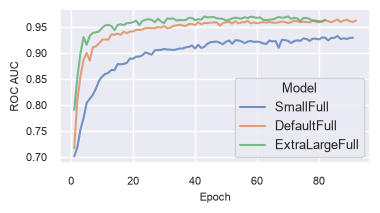

In [162]:
pyplot.rcParams['figure.figsize'] = (4, 2)
pyplot.rcParams['savefig.dpi'] = 400
pyplot.rcParams['savefig.bbox'] = 'tight'
pyplot.rcParams['axes.labelsize'] = 8
pyplot.rcParams['legend.title_fontsize'] = 9
pyplot.rcParams['legend.fontsize'] = 9
pyplot.rcParams['xtick.labelsize'] = 8
pyplot.rcParams['ytick.labelsize'] = 8

for model, df in epochs.groupby('model', sort = False):
    pyplot.plot(df.epoch, df.validation_roc_auc, label = model, ls = '-', alpha = .75)

pyplot.legend(title = 'Model')

pyplot.xlabel('Epoch')
pyplot.ylabel('ROC AUC')

pyplot.savefig('plots/9oct/roc_auc_by_epoch.png')

In [74]:
rocs = pandas.read_csv('data/roc_curves.csv')
rocs

,model,epoch,split,part,source,wandb_roc_auc,recomputed_roc_auc,threshold,false_positive_rate,true_positive_rate
0,SmallFull,86,validation,8,recomputed_from_checkpoint,0.932751,0.932760,inf,0.000000,0.000000
1,SmallFull,86,validation,8,recomputed_from_checkpoint,0.932751,0.932760,9.982787e-01,0.000000,0.000399
2,SmallFull,86,validation,8,recomputed_from_checkpoint,0.932751,0.932760,9.979138e-01,0.000000,0.000799
3,SmallFull,86,validation,8,recomputed_from_checkpoint,0.932751,0.932760,9.977336e-01,0.000000,0.001198
4,SmallFull,86,validation,8,recomputed_from_checkpoint,0.932751,0.932760,9.973198e-01,0.000000,0.001597
...,...,...,...,...,...,...,...,...,...,...
88691,ExtraLargeFull,70,validation,8,recomputed_from_checkpoint,0.970409,0.970409,1.382714e-20,0.999929,1.000000
88692,ExtraLargeFull,70,validation,8,recomputed_from_checkpoint,0.970409,0.970409,1.167979e-20,0.999946,1.000000
88693,ExtraLargeFull,70,validation,8,recomputed_from_checkpoint,0.970409,0.970409,1.130296e-20,0.999964,1.000000
88694,ExtraLargeFull,70,validation,8,recomputed_from_checkpoint,0.970409,0.970409,1.127222e-20,0.999982,1.000000


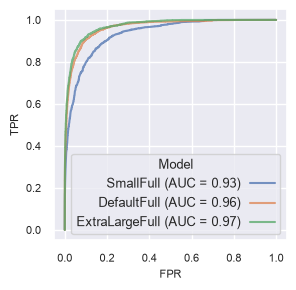

In [167]:
fig, ax = pyplot.subplots(figsize = (3, 3))

roc_aucs = dict(
    SmallFull = 0.932,
    DefaultFull = 0.964,
    ExtraLargeFull = 0.97,
)

for model, df in rocs.groupby('model', sort = False):
    ax.plot(df.false_positive_rate, df.true_positive_rate, label = f'{model} (AUC = {roc_aucs[model]:.2f})', alpha = .75)

ax.legend(title = 'Model', markerfirst = False)
ax.set_xlabel('FPR')
ax.set_ylabel('TPR')

fig.savefig('plots/9oct/roc_per_model')

# Testing

In [12]:
solvable.groupby(['model', 'policy']).proved.sum().sort_values().to_frame()

,,proved
model,policy,
NoModel,satresetcop,325
Reset-SmallFull,satresetcop,374
Reset-DefaultFull,satresetcop,397
Reset-ExtraLargeFull,satresetcop,410
Sat-SmallFull,satcop,425
Sat-DefaultFull,satcop,433
Sat-ExtraLargeFull,satcop,434
NoModel,satcop,441


In [13]:
merged = pandas.merge(solvable, solvable, left_on = 'problem', right_on = 'problem', suffixes = ('_left', '_right'))

In [14]:
better = merged.loc[lambda x: x.proved_left & ~x.proved_right]

In [15]:
crosstab = pandas.crosstab(
    [better.model_left,better.policy_left],
    [better.model_right, better.policy_right],
)
crosstab.index = crosstab.index.map(lambda x: f'{x[0]}-{x[1]}' if x[0] == 'NoModel' else x[0])
crosstab.columns = crosstab.columns.map(lambda x: f'{x[0]}-{x[1]}' if x[0] == 'NoModel' else x[0])

In [16]:
crosstab

,NoModel-satcop,NoModel-satresetcop,Reset-DefaultFull,Reset-ExtraLargeFull,Reset-SmallFull,Sat-DefaultFull,Sat-ExtraLargeFull,Sat-SmallFull
NoModel-satcop,0,135,86,90,98,33,31,38
NoModel-satresetcop,19,0,11,13,7,19,17,19
Reset-DefaultFull,42,83,0,23,39,34,33,40
Reset-ExtraLargeFull,59,98,36,0,53,50,51,55
Reset-SmallFull,31,56,16,17,0,27,25,29
Sat-DefaultFull,25,127,70,73,86,0,16,22
Sat-ExtraLargeFull,24,126,70,75,85,17,0,26
Sat-SmallFull,22,119,68,70,80,14,17,0


Text(0.5, 19.71216362847222, 'Loser')

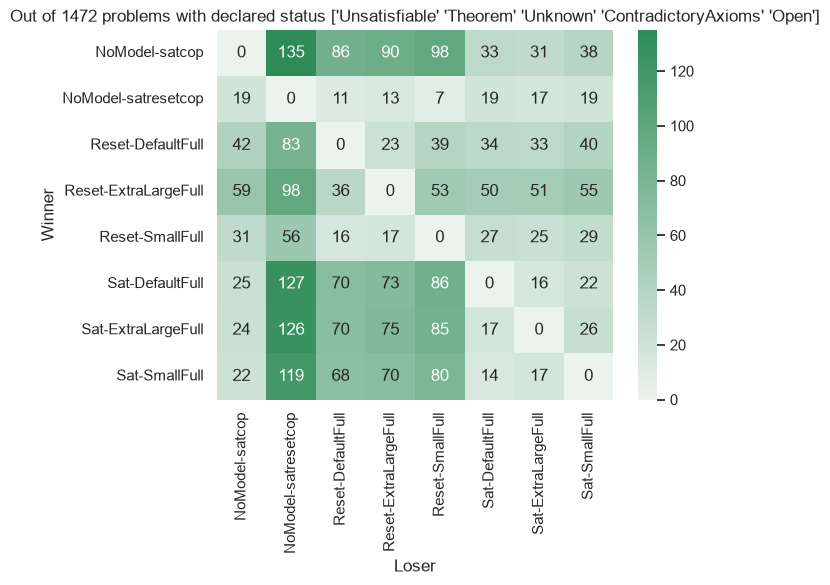

In [17]:
seaborn.heatmap(
    crosstab,
    annot = True,
    fmt = 'd',
    cmap = seaborn.light_palette('seagreen', as_cmap = True)
)

pyplot.title(f'Out of {solvable.problem.nunique()} problems with declared status {solvable.tptp_status.unique()}')
pyplot.ylabel('Winner')
pyplot.xlabel('Loser')

# SATResetCoP alone

In [18]:
src = solvable.loc[lambda x: x.policy == 'satresetcop']

In [101]:
src

,problem,part,tptp_status,model,policy,proved,steps,seconds,proof_size,mode,seed,axioms,prediction_seconds,error
1681,ANA037-2.p,9,Unsatisfiable,NoModel,satresetcop,True,115.0,12.523856,9.0,weighted,0,NaN,NaN,False
1682,ANA038-2.p,9,Unsatisfiable,NoModel,satresetcop,True,115.0,12.504024,9.0,weighted,0,NaN,NaN,False
1683,CAT011-1.p,9,Unsatisfiable,NoModel,satresetcop,True,759.0,0.492865,6.0,weighted,0,NaN,NaN,False
1684,ALG353-1.p,9,Unsatisfiable,NoModel,satresetcop,True,0.0,13.035158,0.0,weighted,0,NaN,NaN,False
1685,ALG341-1.p,9,Unsatisfiable,NoModel,satresetcop,True,228.0,13.591674,4.0,weighted,0,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16905,TOP031+4.p,9,Theorem,Reset-SmallFull,satresetcop,False,NaN,120.001245,NaN,weighted,0,NaN,NaN,False
16906,TOP045+1.p,9,Theorem,Reset-SmallFull,satresetcop,False,NaN,120.000529,NaN,weighted,0,NaN,NaN,False
16907,TOP045+2.p,9,Theorem,Reset-SmallFull,satresetcop,False,NaN,120.002912,NaN,weighted,0,NaN,NaN,False
16908,TOP045+3.p,9,Theorem,Reset-SmallFull,satresetcop,False,NaN,120.001331,NaN,weighted,0,NaN,NaN,False


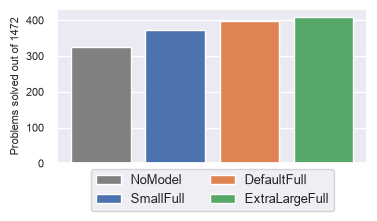

In [186]:
values = src.groupby('model').proved.sum().sort_values()
values.index = values.index.str.removeprefix('Reset-')
bar = pyplot.bar(
    values.index,
    values.values,
    color = ['gray'] + seaborn.color_palette('deep', 3),
    label = values.index,
)

pyplot.xticks([])
pyplot.ylabel('Problems solved out of 1472')
pyplot.legend(loc = 'lower center', ncols = 2, bbox_to_anchor = (.5, -.35))

pyplot.savefig('plots/9oct/solved_per_model')

In [159]:
values

model
NoModel                 325
Reset-SmallFull         374
Reset-DefaultFull       397
Reset-ExtraLargeFull    410
Name: proved, dtype: int64

In [19]:
src.groupby('part').problem.nunique()

part
9    1472
Name: problem, dtype: int64

In [20]:
src.groupby('model').proved.sum().sort_values()

model
NoModel                 325
Reset-SmallFull         374
Reset-DefaultFull       397
Reset-ExtraLargeFull    410
Name: proved, dtype: int64

In [21]:
merged = pandas.merge(src, src, left_on = 'problem', right_on = 'problem', suffixes = ('_left', '_right'))

Text(0.5, 1.0, 'Out of 1472 problems')

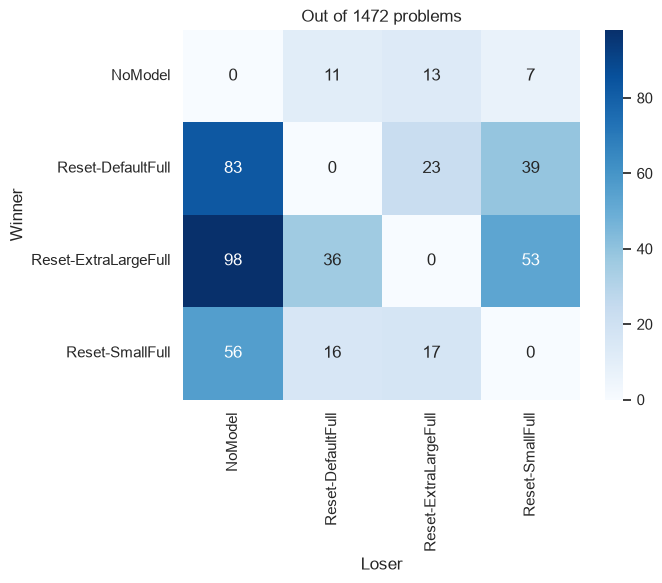

In [22]:
a = merged.loc[lambda x: x.proved_left & ~x.proved_right]
crosstab = pandas.crosstab(a.model_left, a.model_right)
seaborn.heatmap(
    crosstab,
    annot = True,
    cmap = 'Blues',
)

pyplot.ylabel('Winner')
pyplot.xlabel('Loser')
pyplot.title(f'Out of {src.problem.nunique()} problems')

# Invidividual Problems

## SEU143+1.p

 | Order | Description | Source FOF entry | Prolog entries | Score |
  |---:|---|---|---|---:|
  | 1 | Empty-set definition | `d1_xboole_0` | `[eq(A,empty_set), in(B,A)]` | 0.370 |
  | 2 | Singleton definition | `d1_tarski` | `[eq(B,singleton(A)), neg(in(C,B)), eq(C,A)]` | 0.344 |
  | 3 | Equality reflexivity | Generated equality axiom | `[neg(eq(A,A))]` | 0.307 |
  | 4 | Equality symmetry | Generated equality axiom | `[eq(A,B), neg(eq(B,A))]` | 0.228 |
  | 5 | Equality congruence for membership | Generated equality axiom | `[neg(in(B,D)), in(A,C), eq(A,B), eq(C,D)]` | 0.153 |
  | 6 | Equality congruence for `empty` | Generated equality axiom | `[neg(empty(B)), eq(A,B), empty(A)]` | 0.126 |
  | 7 | Singleton definition | `d1_tarski` | `[eq(B,singleton(A)), in(C,B), neg(eq(C,A))]` | 0.089 |
  | 8 | Equality transitivity | Generated equality axiom | `[neg(eq(A,C)), eq(A,B), eq(B,C)]` | 0.040 |
  | 9 | Membership antisymmetry | `antisymmetry_r2_hidden` | `[in(A,B), in(B,A)]` | 0.016 |
  | 10 | Equality congruence for `singleton` | Generated equality axiom | `[eq(A,B), neg(eq(singleton(A),singleton(B)))]` | 0.014 |
  | 11 | Existence of a nonempty set | `rc2_xboole_0` | `[empty(f_skolem(4))]` | 0.005 |
  | 12 | The empty set is empty | `fc1_xboole_0` | `[neg(empty(empty_set))]` | 0.003 |
  | 13 | Existence of an empty set | `rc1_xboole_0` | `[neg(empty(f_skolem(3)))]` | 0.002 |
  | 14 | Empty-set definition, Skolemized | `d1_xboole_0` | `[neg(eq(A,empty_set)), neg(in(f_skolem(2,A),A))]` | 7e-5 |
  | 15 | Singleton definition, Skolemized | `d1_tarski` | `[neg(eq(B,singleton(A))), neg(in(f_skolem(1,B,A),B)), neg(eq(f_skolem(1,B,A),A))]` | 4e-5 |
  | 16 | Singleton definition, Skolemized | `d1_tarski` | `[neg(eq(B,singleton(A))), in(f_skolem(1,B,A),B), eq(f_skolem(1,B,A),A)]` | 1e-6 |

## Everything everywhere all at once

 | Problem | | | | Steps | | | | Time (s) |
  |---|---:|---:|---:|---:|---:|---:|---:|---:|
  | **Model** | **NoModel** | **SmallFull** | **DefaultFull** | **ExtraLargeFull** | **NoModel** | **SmallFull** | **DefaultFull** | **ExtraLargeFull** |
  | SEU143+1 | 1,603 | 10,345 | 322 | 66 | 0.807 | 11.456 | 9.820 | 0.155 |
  | SEU151+1 | 1,205 | 675 | 2,581 | 185 | 0.716 | 6.828 | 2.848 | 0.191 |
  | SET162+3 | 1,396 | 574 | 231 | 103 | 6.604 | 6.752 | 7.718 | 0.203 |
  | SET162+4 | — | 9,603 | 275 | 180 | Timeout | 29.837 | 1.061 | 0.325 |
  | SET634+3 | — | 25,623 | 12,437 | 4,852 | Timeout | 76.960 | 41.312 | 6.517 |
  | GEO189+3 | 61,609 | 3,402 | 1,021 | 656 | 61.635 | 8.611 | 0.986 | 0.502 |
  | GEO201+3 | 3,233 | 1,785 | 705 | 425 | 7.729 | 1.048 | 0.551 | 0.465 |
  | SET881+1 | 5,715 | 359 | 224 | 50 | 16.625 | 6.308 | 0.254 | 6.366 |
  | GRP030-1 | — | — | — | 16,571 | Timeout | Timeout | Timeout | 33.660 |
  | SET909+1 | — | — | — | 1,321 | Timeout | Timeout | Timeout | 7.207 |